# 01 — Storm surge, bathtub method (CLIMADA `TCSurgeBathtub`)

**Goal:** test whether the CLIMADA bathtub surge model fits the Ahead-of-the-Storm (AOS) pipeline:
- **Probabilistic:** one surge result per ECMWF ensemble member, then probability = members above threshold / 51.
- **AOS grid:** results on the AOS zoom-14 Mercator tiles (~2.3 km in Jamaica), the same tiles AOS uses for WorldPop / PIN-CHIN.
- **Fast enough:** runtime measured at every step.

**Test case:** Hurricane Melissa, Jamaica, ECMWF cycle 2025-10-28 00z.

**How AOS gets wind (reproduced here):** ECMWF ensemble 10 m wind (`10u`/`10v`, 0.25°), wind speed = √(u²+v²), max over the forecast steps, per member.

| Step | Input | Output |
|---|---|---|
| 1 | GigaSpatial `MercatorViewGenerator("JAM", 14)` | AOS tiles |
| 2 | GigaSpatial `NasaSRTMHandler` (SRTM 90 m) | Jamaica DEM |
| 3 | ECMWF open data archive (AWS) | 51-member wind GRIB |
| 4 | Wind → tiles | wind matrix (51 × tiles) |
| 5 | Distance to coast + CLIMADA `TCSurgeBathtub` | surge matrix (51 × tiles), metres |
| 6 | Surge → probabilities | P(surge ≥ 0.5 / 1 / 2 / 3 m) per tile |
| 7–10 | Diagnostic, outputs, map, runtime | files in `outputs/` |

**Results of the test run (2026-10-10) and conclusion: see the last section.**

## 0. Setup

Kernel: **`stormsurge_env`**. If `ecmwf-opendata` or `cfgrib` are missing, run once in a terminal (with the env activated):

```bash
pip install ecmwf-opendata cfgrib
```

The first cell must run **before any geospatial import**: it forces the PROJ database of `stormsurge_env`.
Without it, a PROJ installation from the conda `base` environment can be picked up and every projection fails
(`CRSError: Invalid projection: EPSG:4326`).

In [17]:
# Force the PROJ database of this environment (must run before geopandas / rasterio / pyproj)
import os
import sys
from pathlib import Path

proj_dir = str(Path(sys.prefix) / "share" / "proj")
os.environ["PROJ_DATA"] = proj_dir
os.environ["PROJ_LIB"] = proj_dir

import pyproj
pyproj.datadir.set_data_dir(proj_dir)
print("Python:", sys.executable)
print("PROJ:", proj_dir, "| proj.db found:", (Path(proj_dir) / "proj.db").exists(), "| test:", pyproj.CRS("EPSG:4326").name)

Python: /opt/anaconda3/envs/stormsurge_env/bin/python
PROJ: /opt/anaconda3/envs/stormsurge_env/share/proj | proj.db found: True | test: WGS 84


In [18]:
import time
import zipfile
from datetime import datetime

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import rasterio
from rasterio.merge import merge as rio_merge
from scipy import sparse
from dotenv import load_dotenv
import matplotlib.pyplot as plt

In [19]:
# Project root = the folder that contains data/, notebooks/, outputs/ and .env
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT / ".env")   # Earthdata credentials (never printed)

CONFIG = {
    # Test case
    "storm_name": "MELISSA",
    "country_iso3": "JAM",
    "cycle_date": "2025-10-28",
    "cycle_time": 0,                         # 00z
    "forecast_steps_h": list(range(0, 49, 3)),  # 0-48 h, 3-hourly (landfall ~+17 h)

    # AOS conventions
    "zoom_level": 14,                        # AOS tile grid
    "n_members_expected": 51,                # ENS: 1 control + 50 perturbed
    "wind_min_ms": 17.49,                    # 34 kt = lowest AOS wind threshold

    # Elevation
    "srtm_resolution": "90m",

    # Surge
    "surge_thresholds_m": [0.5, 1.0, 2.0, 3.0],
    "inland_decay_m_per_km": 0.2,            # CLIMADA default
    "sea_level_rise_m": 0.0,

    # Paths
    "bufr_file": PROJECT / "data/bufr/20251028_00z_tf.bufr",
    "grid_file": PROJECT / "data/grid/JAM_z14_tiles.parquet",
    "srtm_raw_dir": PROJECT / "data/dem/srtm_raw",
    "dem_file": PROJECT / "data/dem/JAM_srtm90.tif",
    "wind_grib": PROJECT / "data/wind/ecmwf_enfo_10uv_20251028_00z_0-48h.grib2",
    "output_dir": PROJECT / "outputs",
}

for key in ("srtm_raw_dir", "output_dir"):
    CONFIG[key].mkdir(parents=True, exist_ok=True)
for key in ("grid_file", "dem_file", "wind_grib"):
    CONFIG[key].parent.mkdir(parents=True, exist_ok=True)

TIMINGS = {}   # step name -> seconds

class timer:
    # Usage: `with timer("step name"):` -> stores runtime in TIMINGS
    def __init__(self, name): self.name = name
    def __enter__(self): self.t0 = time.perf_counter()
    def __exit__(self, *exc):
        TIMINGS[self.name] = time.perf_counter() - self.t0
        print(f"[{self.name}] {TIMINGS[self.name]:.1f} s")

print("Project:", PROJECT)
print("Earthdata user set:", bool(os.getenv("EARTHDATA_USERNAME")))

Project: /Users/nassimdekkar/unicef/stormsurge
Earthdata user set: True


## 1. AOS grid — zoom-14 Mercator tiles for Jamaica

Same call as AOS (`impact_analysis.py`): `MercatorViewGenerator(source=country, zoom_level=14)`.
The tile id (`quadkey`) is the same as AOS's `tile_id`, so the surge results can be joined directly to AOS population.
Cached to `data/grid/` after the first run.

In [20]:
from gigaspatial.generators import MercatorViewGenerator

with timer("1_grid"):
    if CONFIG["grid_file"].exists():
        tiles = gpd.read_parquet(CONFIG["grid_file"])
    else:
        gen = MercatorViewGenerator(source=CONFIG["country_iso3"], zoom_level=CONFIG["zoom_level"])
        tiles = gen.zone_gdf.rename(columns={"zone_id": "tile_id"})
        tiles = tiles.set_crs("EPSG:4326") if tiles.crs is None else tiles.to_crs("EPSG:4326")
        tiles.to_parquet(CONFIG["grid_file"])

# Tile centres = computation points for CLIMADA
centres = tiles.geometry.to_crs("EPSG:3857").centroid.to_crs("EPSG:4326")
tiles["lon"] = centres.x.values
tiles["lat"] = centres.y.values

print(f"{len(tiles)} tiles | bounds: {tiles.total_bounds.round(3)}")
tiles.head()

[1_grid] 0.1 s
2234 tiles | bounds: [-78.376  17.015 -75.959  18.542]


,tile_id,geometry,lon,lat
0,03221023133310,"POLYGON ((-75.95947 17.37161, -75.95947 17.392...",-75.970459,17.382095
1,03221023133301,"POLYGON ((-75.98145 17.37161, -75.98145 17.392...",-75.992432,17.382095
2,03221023133123,"POLYGON ((-75.98145 17.39258, -75.98145 17.413...",-75.992432,17.403063
3,03221023133132,"POLYGON ((-75.95947 17.39258, -75.95947 17.413...",-75.970459,17.403063
4,03221023133130,"POLYGON ((-75.95947 17.41355, -75.95947 17.434...",-75.970459,17.424029


## 2. Elevation — SRTM 90 m via GigaSpatial

`NasaSRTMHandler` downloads the 1°×1° SRTM tiles covering Jamaica (Earthdata login from `.env`).
Tiles that are fully ocean do not exist on the NASA server: an error for those in the log is expected.
The tiles are then merged into one GeoTIFF for CLIMADA.

In [21]:
from gigaspatial.handlers.nasa import NasaSRTMHandler
from gigaspatial.handlers.nasa.srtm import NasaSRTMConfig

with timer("2_dem"):
    if not CONFIG["dem_file"].exists():
        srtm_config = NasaSRTMConfig(
            resolution=CONFIG["srtm_resolution"],
            base_path=CONFIG["srtm_raw_dir"],
            earthdata_username=os.environ["EARTHDATA_USERNAME"],
            earthdata_password=os.environ["EARTHDATA_PASSWORD"],
        )
        srtm = NasaSRTMHandler(config=srtm_config)

        area = tiles.geometry.union_all() if hasattr(tiles.geometry, "union_all") else tiles.unary_union
        srtm.ensure_data_available(source=area)

        units = srtm_config.get_relevant_data_units(area)
        zips = [p for p in srtm_config.get_data_unit_paths(units) if Path(p).exists()]
        print(f"{len(zips)} SRTM tiles available:", [Path(p).name for p in zips])

        # Unzip the .hgt files and merge them into one GeoTIFF
        hgt_files = []
        for z in zips:
            with zipfile.ZipFile(z) as zf:
                for name in zf.namelist():
                    if name.lower().endswith(".hgt"):
                        zf.extract(name, CONFIG["srtm_raw_dir"])
                        hgt_files.append(CONFIG["srtm_raw_dir"] / name)

        sources = [rasterio.open(f) for f in hgt_files]
        mosaic, transform = rio_merge(sources)
        profile = sources[0].profile.copy()
        profile.update(driver="GTiff", height=mosaic.shape[1], width=mosaic.shape[2],
                       transform=transform, compress="deflate")
        for s in sources:
            s.close()
        with rasterio.open(CONFIG["dem_file"], "w", **profile) as dst:
            dst.write(mosaic)

with rasterio.open(CONFIG["dem_file"]) as dem:
    print("DEM:", dem.width, "x", dem.height, "| res (deg):", dem.res, "| nodata:", dem.nodata)

[2_dem] 0.0 s
DEM: 4801 x 2401 | res (deg): (0.0008333333333333334, 0.0008333333333333334) | nodata: -32768.0


## 3. ECMWF ensemble wind — same data as AOS

AOS downloads `10u`/`10v` from ECMWF open data. ECMWF's own server keeps only the last days, so for October 2025 we use the **ECMWF open data archive on AWS** (`source="aws"`, same files).

- `type=["cf", "pf"]`: control + 50 perturbed members = 51 members (the ENS structure in October 2025).
- Steps 0–48 h every 3 h, one global file (~ about 1 GB, downloaded once).

In [22]:
from ecmwf.opendata import Client

with timer("3_wind_download"):
    if not CONFIG["wind_grib"].exists():
        client = Client(source="aws")
        client.retrieve(
            date=CONFIG["cycle_date"],
            time=CONFIG["cycle_time"],
            stream="enfo",
            type=["cf", "pf"],
            step=CONFIG["forecast_steps_h"],
            param=["10u", "10v"],
            target=str(CONFIG["wind_grib"]),
        )

print(f"Wind GRIB: {CONFIG['wind_grib'].stat().st_size / 1e6:.0f} MB")

[3_wind_download] 0.0 s
Wind GRIB: 1401 MB


## 4. Wind on the AOS tiles

Same as AOS: speed = √(u² + v²) per member and step, then **max over the forecast steps** (AOS merges its envelopes over all steps).
The 0.25° wind is interpolated (bilinear) at each tile centre.
Wind below 34 kt (17.49 m/s, lowest AOS threshold) is set to 0: no storm wind, no surge.

In [23]:
# Read only a box around Jamaica (+1 degree margin)
lon_min, lat_min, lon_max, lat_max = tiles.total_bounds
margin = 1.0

def read_wind(data_type):
    ds = xr.open_dataset(CONFIG["wind_grib"], engine="cfgrib",
                         backend_kwargs={"filter_by_keys": {"dataType": data_type},
                                         "indexpath": ""})
    if float(ds.longitude.max()) > 180:   # 0..360 -> -180..180
        ds = ds.assign_coords(longitude=((ds.longitude + 180) % 360) - 180).sortby("longitude")
    ds = ds.sortby("latitude")
    ds = ds.sel(latitude=slice(lat_min - margin, lat_max + margin),
                longitude=slice(lon_min - margin, lon_max + margin))
    speed = np.sqrt(ds["u10"] ** 2 + ds["v10"] ** 2)
    if "number" not in speed.dims:                   # control file has a single member
        speed = speed.expand_dims("number") if "number" in speed.coords else speed.expand_dims(number=[0])
    return speed.max(dim="step").load()             # max over forecast steps

with timer("4_wind_to_tiles"):
    wind_max = xr.concat([read_wind("cf"), read_wind("pf")], dim="number").sortby("number")

    pts_lat = xr.DataArray(tiles["lat"].values, dims="tile")
    pts_lon = xr.DataArray(tiles["lon"].values, dims="tile")
    wind_tiles = wind_max.interp(latitude=pts_lat, longitude=pts_lon, method="linear")
    wind_ms = np.nan_to_num(wind_tiles.transpose("number", "tile").values)   # (members, tiles)
    wind_ms[wind_ms < CONFIG["wind_min_ms"]] = 0.0

members = wind_max["number"].values
print(f"Members: {len(members)} (expected {CONFIG['n_members_expected']})")
print(f"Wind matrix: {wind_ms.shape} | max wind on tiles: {wind_ms.max():.1f} m/s ({wind_ms.max() / 0.514444:.0f} kt)")

[4_wind_to_tiles] 30.7 s
Members: 51 (expected 51)
Wind matrix: (51, 2234) | max wind on tiles: 55.7 m/s (108 kt)


## 5. Surge — CLIMADA `TCSurgeBathtub`

### 5a. Distance to coast per tile

CLIMADA normally reads its distance to coast from a 300 MB NASA file (`oceancolor.gsfc.nasa.gov`), and that server
blocks the download (HTTP 403). We compute it ourselves from the Jamaica boundary that GigaSpatial already used to build
the AOS grid (same source, no external file). Convention as in CLIMADA: metres, **negative on land**, positive at sea.

In [24]:
from gigaspatial.handlers import AdminBoundaries

with timer("5a_dist_coast"):
    country = gpd.GeoSeries(
        [AdminBoundaries.create(country_code=CONFIG["country_iso3"]).to_geoms()[0]],
        crs="EPSG:4326",
    )
    utm = country.estimate_utm_crs()                  # metric CRS for distances
    country_m = country.to_crs(utm).iloc[0]
    pts_m = gpd.GeoSeries(gpd.points_from_xy(tiles["lon"], tiles["lat"]), crs="EPSG:4326").to_crs(utm)

    dist_m = pts_m.distance(country_m.boundary).values
    on_land = pts_m.within(country_m).values
    tiles["dist_coast_m"] = np.where(on_land, -dist_m, dist_m)

print(f"Tiles within 50 km of the coast: {(np.abs(tiles['dist_coast_m']) <= 50_000).sum()} / {len(tiles)}")

INFO        AdminBoundaries 2026-10-10 13:06:01,566       : AdminBoundaries.create country=JAM level=0 data_store=False path=False
WARNING     AdminBoundaries 2026-10-10 13:06:01,605       : GeoRepo check failed: API Key is required. Provide it as a parameter or set GEOREPO_API_KEY environment variable.
INFO        AdminBoundaries 2026-10-10 13:06:01,605       : Attempting GADM fallback.
INFO        AdminBoundaries 2026-10-10 13:06:01,606       : Loading GADM data for JAM admin_level=0 from https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_JAM_0.json
INFO        EntityManager 2026-10-10 13:06:02,351       : Validating AdminBoundary entities:   0%|          | 0/1 [00:00<?, ?it/s]
INFO        EntityManager 2026-10-10 13:06:02,357       : Validating AdminBoundary entities: 100%|##########| 1/1 [00:00<00:00, 174.06it/s]
INFO        EntityManager 2026-10-10 13:06:02,358       : 


[5a_dist_coast] 0.9 s
Tiles within 50 km of the coast: 2234 / 2234


### 5b. Bathtub surge

The ECMWF wind matrix is wrapped in a CLIMADA `Hazard` (one event per member), then passed to `TCSurgeBathtub.from_tc_winds`.
The centroids use the distance to coast from 5a instead of the NASA file.

What CLIMADA does per tile (only tiles ≤ 50 km from the coast and with elevation between 0 and 10 m):
`surge = 0.1023 × max(wind − 26.8, 0) + 1.83  −  elevation  −  0.2 × distance_to_coast_km`, negatives set to 0.

We only use the surge **height** (`intensity`). CLIMADA's land-fraction output assumes a regular grid, so it is not
meaningful on AOS tiles and is ignored.

In [25]:
from climada.hazard import Centroids, Hazard
from climada_petals.hazard import TCSurgeBathtub

n_mem, n_tiles = wind_ms.shape
centroids = Centroids(lat=tiles["lat"].values, lon=tiles["lon"].values)

# Use our distance to coast (5a) instead of CLIMADA's NASA file
_dist = tiles["dist_coast_m"].values
centroids.get_dist_coast = lambda signed=False, precomputed=True: _dist if signed else np.abs(_dist)

wind_haz = Hazard(
    haz_type="TC",
    units="m/s",
    centroids=centroids,
    event_id=np.arange(1, n_mem + 1),
    event_name=[f"{CONFIG['storm_name']}_m{int(m):02d}" for m in members],
    frequency=np.full(n_mem, 1.0 / n_mem),
    date=np.full(n_mem, datetime.strptime(CONFIG["cycle_date"], "%Y-%m-%d").toordinal()),
    orig=np.zeros(n_mem, dtype=bool),
    intensity=sparse.csr_matrix(wind_ms),
    fraction=sparse.csr_matrix((n_mem, n_tiles)),
)
wind_haz.check()

with timer("5_surge_bathtub"):
    surge_haz = TCSurgeBathtub.from_tc_winds(
        wind_haz,
        str(CONFIG["dem_file"]),
        inland_decay_rate=CONFIG["inland_decay_m_per_km"],
        add_sea_level_rise=CONFIG["sea_level_rise_m"],
    )

surge_m = surge_haz.intensity.toarray()   # (members, tiles), metres
print(f"Surge matrix: {surge_m.shape} | tiles with surge in >=1 member: {(surge_m.max(axis=0) > 0).sum()} | max: {surge_m.max():.2f} m")

[5_surge_bathtub] 0.3 s
Surge matrix: (51, 2234) | tiles with surge in >=1 member: 17 | max: 2.78 m


## 6. Probabilities per tile (AOS logic: members above threshold / 51)

In [26]:
with timer("6_probabilities"):
    result = tiles[["tile_id", "lat", "lon", "geometry"]].copy()
    result["surge_max_m"] = surge_m.max(axis=0)
    result["surge_mean_m"] = surge_m.mean(axis=0)
    for thr in CONFIG["surge_thresholds_m"]:
        result[f"prob_surge_{thr:g}m"] = (surge_m >= thr).mean(axis=0)

prob_cols = [c for c in result.columns if c.startswith("prob_surge_")]
summary = pd.DataFrame({
    "threshold": prob_cols,
    "tiles_prob_gt_0": [(result[c] > 0).sum() for c in prob_cols],
    "tiles_prob_ge_50pct": [(result[c] >= 0.5).sum() for c in prob_cols],
})
summary

[6_probabilities] 0.0 s


,threshold,tiles_prob_gt_0,tiles_prob_ge_50pct
0,prob_surge_0.5m,14,6
1,prob_surge_1m,10,2
2,prob_surge_2m,3,0
3,prob_surge_3m,0,0


## 7. Diagnostic — elevation of coastal tiles

Why do only a few tiles get surge? The bathtub uses **one elevation per tile**, sampled at the tile centre.
This cell shows the centre elevation of the coastal tiles (centre less than 3 km inland) and, for the south-west
coast where Melissa made landfall (Black River / Savanna-la-Mar), elevation, wind and surge per tile.

In [27]:
from climada.util.coordinates import read_raster_sample

diag = tiles[["tile_id", "lon", "lat", "dist_coast_m"]].copy()
diag["elev_centre_m"] = read_raster_sample(str(CONFIG["dem_file"]), diag["lat"].values, diag["lon"].values)
diag["wind_max_ms"] = wind_ms.max(axis=0)
diag["surge_max_m"] = surge_m.max(axis=0)

coastal = diag[diag["dist_coast_m"].between(-3000, 0)]
print(f"Coastal tiles (centre < 3 km inland): {len(coastal)}")
print(f"  centre elevation: median {coastal['elev_centre_m'].median():.0f} m | "
      f"<= 3 m: {(coastal['elev_centre_m'] <= 3).sum()} tiles | < 0 m: {(coastal['elev_centre_m'] < 0).sum()} tiles")

west = coastal[coastal["lon"] < -77.6].sort_values("elev_centre_m")
west[["tile_id", "lon", "lat", "dist_coast_m", "elev_centre_m", "wind_max_ms", "surge_max_m"]].head(15).round(2)

Coastal tiles (centre < 3 km inland): 354
  centre elevation: median 47 m | <= 3 m: 24 tiles | < 0 m: 6 tiles


,tile_id,lon,lat,dist_coast_m,elev_centre_m,wind_max_ms,surge_max_m
823,03221020323232,-77.82,17.99,-1851.50,-1.94,39.93,0.00
851,03221020323212,-77.82,18.03,-2983.31,-1.19,37.90,0.00
826,03221020323230,-77.82,18.01,-1852.52,-0.90,38.96,0.00
828,03221020323203,-77.84,18.03,-1403.64,0.89,38.57,1.86
740,03221022101300,-77.77,17.88,-64.84,1.39,44.27,2.21
769,03221020322303,-77.93,18.03,-7.31,1.79,42.78,1.67
1854,03221020212231,-78.32,18.34,-1442.83,2.10,45.29,1.33
2077,03221020310223,-77.66,18.49,-610.13,2.18,37.97,0.67
926,03221020231301,-78.10,18.22,-560.06,2.71,34.81,0.00
2171,03221020301321,-77.75,18.51,-207.27,3.03,40.57,0.17


## 8. Save outputs

- `surge_by_member.parquet`: one row per (tile, member) with surge > 0 — sparse, same idea as AOS river-flood `extent_bymember`.
- `surge_prob_by_tile.parquet`: one row per tile with the exceedance probabilities.

In [28]:
tag = f"{CONFIG['storm_name'].lower()}_{CONFIG['cycle_date'].replace('-', '')}_{CONFIG['cycle_time']:02d}z"

rows, cols = np.nonzero(surge_m)
by_member = pd.DataFrame({
    "tile_id": tiles["tile_id"].values[cols],
    "member": members[rows].astype(int),
    "surge_m": surge_m[rows, cols].round(3),
})
by_member.to_parquet(CONFIG["output_dir"] / f"{tag}_surge_by_member.parquet", index=False)
result.to_parquet(CONFIG["output_dir"] / f"{tag}_surge_prob_by_tile.parquet", index=False)
print(f"Saved {len(by_member)} member rows and {len(result)} tile rows to {CONFIG['output_dir']}")

Saved 382 member rows and 2234 tile rows to /Users/nassimdekkar/unicef/stormsurge/outputs


## 9. Map — probability of surge ≥ 1 m, with the ensemble tracks

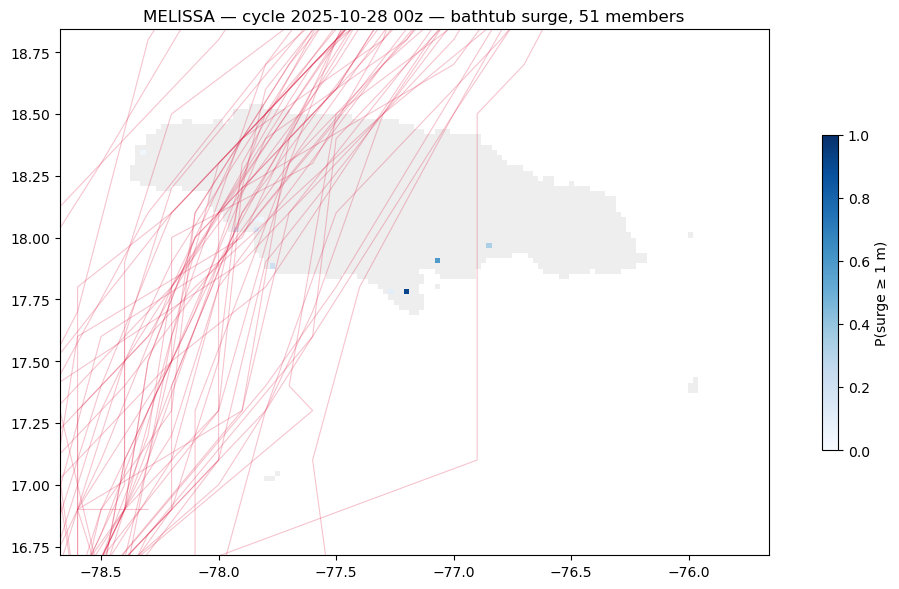

In [29]:
from climada_petals.hazard.tc_tracks_forecast import TCForecast

fc = TCForecast()
fc.read_one_bufr_tc(str(CONFIG["bufr_file"]))
tracks = [t for t in fc.data if t.name.upper() == CONFIG["storm_name"]]

fig, ax = plt.subplots(figsize=(11, 6))
tiles.plot(ax=ax, color="#eeeeee", edgecolor="none")
hit = result[result["prob_surge_1m"] > 0]
hit.plot(ax=ax, column="prob_surge_1m", cmap="Blues", vmin=0, vmax=1, legend=True,
         legend_kwds={"label": "P(surge ≥ 1 m)", "shrink": 0.6})
for t in tracks:
    ax.plot(t.lon, t.lat, color="crimson", alpha=0.25, linewidth=0.8)
ax.set_xlim(lon_min - 0.3, lon_max + 0.3)
ax.set_ylim(lat_min - 0.3, lat_max + 0.3)
ax.set_title(f"{CONFIG['storm_name']} — cycle {CONFIG['cycle_date']} {CONFIG['cycle_time']:02d}z — bathtub surge, {len(members)} members")
plt.tight_layout()
plt.savefig(CONFIG["output_dir"] / f"{tag}_map_prob_surge_1m.png", dpi=150)
plt.show()

## 10. Runtime summary

Download steps (grid, DEM, wind) happen once, or are already done by the AOS pipeline in production.
The numbers that matter for the hourly constraint are **4 (wind → tiles)**, **5 (distance to coast + surge)** and **6 (probabilities)**.

In [30]:
timings = pd.Series(TIMINGS, name="seconds").round(2)
compute = timings[[k for k in timings.index if k.startswith(("4_", "5", "6_"))]].sum()
print(timings.to_string())
print(f"\nCompute per storm/cycle (steps 4-6): {compute:.1f} s for {n_tiles} tiles x {n_mem} members")
timings.to_csv(CONFIG["output_dir"] / f"{tag}_timings.csv")

1_grid              0.05
2_dem               0.00
3_wind_download     0.00
4_wind_to_tiles    30.68
5a_dist_coast       0.90
5_surge_bathtub     0.33
6_probabilities     0.01

Compute per storm/cycle (steps 4-6): 31.9 s for 2234 tiles x 51 members
